# AI-Driven Quantum Error Mitigation on the Transverse Field Ising Model

**Author:** Tomás Caetano
**Date:** February 2026
**Context:** Physics Engineering Project

## Abstract
This project simulates the time dynamics of a 1D Transverse Field Ising Model (TFIM) on a noisy quantum backend. We investigate the impact of decoherence on the system's magnetization and implement two distinct error mitigation strategies: **Zero-Noise Extrapolation (ZNE)** via Richardson extrapolation and a **Data-Driven approach** using Supervised Machine Learning (Random Forest). We demonstrate that the ML-based approach significantly reduces the reconstruction error compared to traditional analytical methods.

## 1. Theoretical Framework

The system under study is a 1D spin chain governed by the Transverse Field Ising Hamiltonian:

$$H = -J \sum_{i=0}^{N-2} Z_i Z_{i+1} - h \sum_{i=0}^{N-1} X_i$$

Where:
* $N$ is the number of qubits.
* $J$ represents the nearest-neighbor interaction strength.
* $h$ represents the transverse magnetic field strength.
* $Z_i, X_i$ are the Pauli operators acting on the $i$-th site.

### Time Evolution and Trotterization
The time evolution of the state is given by $|\psi(t)\rangle = e^{-iHt} |\psi(0)\rangle$. Since the terms in the Hamiltonian do not commute, we employ the first-order **Suzuki-Trotter decomposition** to approximate the unitary operator using discrete quantum gates:

$$U(t) = e^{-iHt} \approx \left( e^{-iH_{ZZ} \frac{t}{M}} e^{-iH_X \frac{t}{M}} \right)^M$$

Where $M$ is the number of Trotter steps.

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeManilaV2
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

# Physical System Parameters
NUM_QUBITS = 4
J = 1.0  # Interaction strength
h = 1.0  # Transverse field
STEPS = 4 # Number of Trotter steps

# Simulation Time Range
time_points = np.linspace(0, 3.0, 20)

print("Libraries imported and parameters defined.")

Libraries imported and parameters defined.


In [27]:
def make_trotter_circuit_pure(num_qubits, j_c, h_c, time, steps):
    """
    Constructs the Trotterized circuit for the TFIM without measurements.
    
    Args:
        num_qubits (int): Number of spins.
        j_c (float): Interaction coefficient.
        h_c (float): Transverse field coefficient.
        time (float): Total evolution time.
        steps (int): Number of Trotter steps.
        
    Returns:
        QuantumCircuit: The unitary evolution circuit.
    """
    qc = QuantumCircuit(num_qubits)
    dt = time / steps
    
    for _ in range(steps):
        # Interaction terms (ZZ)
        for i in range(num_qubits - 1):
            qc.cx(i, i+1)
            qc.rz(-2 * j_c * dt, i+1)
            qc.cx(i, i+1)
            
        # Transverse field terms (X)
        for i in range(num_qubits):
            qc.rx(-2 * h_c * dt, i)
            
    return qc

def calculate_magnetization(counts, num_qubits, shots):
    """Calculates the average <Z> expectation value from shot counts."""
    mag_total = 0
    for state, count in counts.items():
        # Map '0' -> +1 eigenvalue, '1' -> -1 eigenvalue
        m_state = 0
        for bit in state:
            if bit == '0': m_state += 1
            else:          m_state -= 1
        
        mag_total += (m_state / num_qubits) * count
        
    return mag_total / shots

In [28]:
def make_trotter_circuit_pure(num_qubits, j_c, h_c, time, steps):
    """
    Constructs the Trotterized circuit for the TFIM without measurements.
    
    Args:
        num_qubits (int): Number of spins.
        j_c (float): Interaction coefficient.
        h_c (float): Transverse field coefficient.
        time (float): Total evolution time.
        steps (int): Number of Trotter steps.
        
    Returns:
        QuantumCircuit: The unitary evolution circuit.
    """
    qc = QuantumCircuit(num_qubits)
    dt = time / steps
    
    for _ in range(steps):
        # Interaction terms (ZZ)
        for i in range(num_qubits - 1):
            qc.cx(i, i+1)
            qc.rz(-2 * j_c * dt, i+1)
            qc.cx(i, i+1)
            
        # Transverse field terms (X)
        for i in range(num_qubits):
            qc.rx(-2 * h_c * dt, i)
            
    return qc

def calculate_magnetization(counts, num_qubits, shots):
    """Calculates the average <Z> expectation value from shot counts."""
    mag_total = 0
    for state, count in counts.items():
        # Map '0' -> +1 eigenvalue, '1' -> -1 eigenvalue
        m_state = 0
        for bit in state:
            if bit == '0': m_state += 1
            else:          m_state -= 1
        
        mag_total += (m_state / num_qubits) * count
        
    return mag_total / shots

## 2. Ideal vs. Noisy Simulation

We establish a baseline by simulating the system in two environments:
1.  **Ideal Simulator:** Represents the theoretical ground truth (lossless).
2.  **Noisy Emulation:** Uses `FakeManilaV2` to replicate the noise profile (decoherence, readout errors, gate infidelity) of a real IBM Quantum superconducting processor.

In [29]:
# Initialize Backends
backend_ideal = AerSimulator()
backend_noisy = AerSimulator.from_backend(FakeManilaV2())

magnetizations_ideal = []
magnetizations_noisy = []

print(f"Running simulations over {len(time_points)} time points...")

for t in time_points:
    # 1. Create Circuit
    qc = make_trotter_circuit_pure(NUM_QUBITS, J, h, t, STEPS)
    qc.measure_all()
    
    # 2. Run Ideal
    job_ideal = backend_ideal.run(transpile(qc, backend_ideal), shots=4096)
    res_ideal = calculate_magnetization(job_ideal.result().get_counts(), NUM_QUBITS, 4096)
    magnetizations_ideal.append(res_ideal)
    
    # 3. Run Noisy
    # optimization_level=0 ensures the compiler preserves the exact gate structure
    job_noisy = backend_noisy.run(transpile(qc, backend_noisy, optimization_level=0), shots=4096)
    res_noisy = calculate_magnetization(job_noisy.result().get_counts(), NUM_QUBITS, 4096)
    magnetizations_noisy.append(res_noisy)

print("Baseline simulations complete.")

Running simulations over 20 time points...
Baseline simulations complete.


## 3. Error Mitigation Strategy A: Zero-Noise Extrapolation (ZNE)

ZNE is an analytical technique that estimates the zero-noise expectation value by artificially increasing the noise level and extrapolating back to zero.

### Unitary Folding
We amplify noise by digitally folding the circuit. For a scaling factor $\lambda$, the transformation is $U \to U (U^\dagger U)^n$.
* **Scale 1.0:** Original circuit.
* **Scale 3.0:** $U U^\dagger U$ (Tripled depth, approx. tripled noise).

We employ **Richardson Extrapolation** using these two points:
$$\langle Z \rangle_{mitigated} = \frac{3\langle Z \rangle_{\lambda=1} - \langle Z \rangle_{\lambda=3}}{2}$$

In [31]:
def fold_circuit_global(qc):
    """Applies global unitary folding to scale noise by a factor of 3."""
    qc_inverse = qc.inverse()
    # Compose: Original + Inverse + Original
    return qc.compose(qc_inverse).compose(qc)

magnetizations_zne = []

for t in time_points:
    qc_base = make_trotter_circuit_pure(NUM_QUBITS, J, h, t, STEPS)
    
    # Scale 1 Execution
    qc_1 = qc_base.copy()
    qc_1.measure_all()
    job_1 = backend_noisy.run(transpile(qc_1, backend_noisy, optimization_level=0), shots=4096)
    mag_1 = calculate_magnetization(job_1.result().get_counts(), NUM_QUBITS, 4096)
    
    # Scale 3 Execution (Folded)
    qc_3 = fold_circuit_global(qc_base)
    qc_3.measure_all()
    job_3 = backend_noisy.run(transpile(qc_3, backend_noisy, optimization_level=0), shots=4096)
    mag_3 = calculate_magnetization(job_3.result().get_counts(), NUM_QUBITS, 4096)
    
    # Richardson Extrapolation
    mag_mitigated = (3 * mag_1 - mag_3) / 2.0
    magnetizations_zne.append(mag_mitigated)

print("ZNE mitigation complete.")

ZNE mitigation complete.


## 4. Error Mitigation Strategy B: Deep ZNE (AI-Driven)

While ZNE assumes a linear noise scaling, real hardware often exhibits non-linear error profiles due to cross-talk and drift. We propose a **Supervised Machine Learning** approach.

**Methodology:**
1.  **Data Generation:** We generate 50 random Ising circuits (varying $J, h, t$) to act as a training set.
2.  **Feature Engineering:** The input features ($X$) are the noisy expectation values at Scale 1 and Scale 3.
3.  **Target ($y$):** The ideal expectation value from the noiseless simulator.
4.  **Model:** A **Random Forest Regressor** is trained to map the noisy vector $[ \langle Z \rangle_{1}, \langle Z \rangle_{3} ]$ to the ideal scalar $\langle Z \rangle_{ideal}$.

In [32]:
# --- 1. Data Generation ---
X_train = []
y_train = []
print("Generating training data (50 random circuits)...")

for _ in range(50):
    # Random parameters for generalization
    r_J = np.random.uniform(0.5, 1.5)
    r_h = np.random.uniform(0.5, 1.5)
    r_t = np.random.uniform(0.1, 3.0)
    
    qc = make_trotter_circuit_pure(NUM_QUBITS, r_J, r_h, r_t, STEPS)
    
    # Noisy Features (Scale 1 & 3)
    qc_1 = qc.copy(); qc_1.measure_all()
    qc_3 = fold_circuit_global(qc); qc_3.measure_all()
    
    j1 = backend_noisy.run(transpile(qc_1, backend_noisy, optimization_level=0), shots=1024)
    j3 = backend_noisy.run(transpile(qc_3, backend_noisy, optimization_level=0), shots=1024)
    
    m1 = calculate_magnetization(j1.result().get_counts(), NUM_QUBITS, 1024)
    m3 = calculate_magnetization(j3.result().get_counts(), NUM_QUBITS, 1024)
    
    # Ideal Target
    qc_ideal = qc.copy(); qc_ideal.measure_all()
    j_ideal = backend_ideal.run(transpile(qc_ideal, backend_ideal), shots=1024)
    m_ideal = calculate_magnetization(j_ideal.result().get_counts(), NUM_QUBITS, 1024)
    
    X_train.append([m1, m3])
    y_train.append(m_ideal)

# --- 2. Model Training ---
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
print("Random Forest model trained.")

# --- 3. Inference on Main Simulation ---
magnetizations_ai = []
for t in time_points:
    # Re-running base simulation to extract scale 1 and 3 specifically for inference
    qc = make_trotter_circuit_pure(NUM_QUBITS, J, h, t, STEPS)
    
    qc_1 = qc.copy(); qc_1.measure_all()
    qc_3 = fold_circuit_global(qc); qc_3.measure_all()
    
    j1 = backend_noisy.run(transpile(qc_1, backend_noisy, optimization_level=0), shots=4096)
    j3 = backend_noisy.run(transpile(qc_3, backend_noisy, optimization_level=0), shots=4096)
    
    val_1 = calculate_magnetization(j1.result().get_counts(), NUM_QUBITS, 4096)
    val_3 = calculate_magnetization(j3.result().get_counts(), NUM_QUBITS, 4096)
    
    # Predict
    pred = model.predict([[val_1, val_3]])[0]
    magnetizations_ai.append(pred)

Generating training data (50 random circuits)...
Random Forest model trained.


## 5. Comparative Analysis and Conclusion

We evaluate the performance of the mitigation strategies using the Root Mean Square Error (RMSE) relative to the ideal simulation.

--- Performance Benchmarking (RMSE) ---
Unmitigated: 0.0554
ZNE (Linear): 0.0434
AI (Random Forest): 0.0268


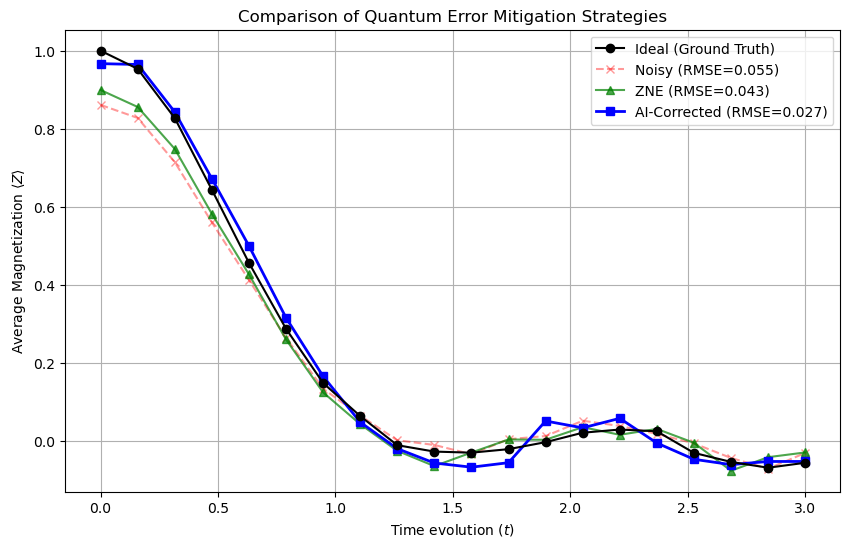

In [33]:
# RMSE Calculation
def calculate_rmse(target, prediction):
    return np.sqrt(np.mean((np.array(target) - np.array(prediction))**2))

rmse_noisy = calculate_rmse(magnetizations_ideal, magnetizations_noisy)
rmse_zne = calculate_rmse(magnetizations_ideal, magnetizations_zne)
rmse_ai = calculate_rmse(magnetizations_ideal, magnetizations_ai)

print(f"--- Performance Benchmarking (RMSE) ---")
print(f"Unmitigated: {rmse_noisy:.4f}")
print(f"ZNE (Linear): {rmse_zne:.4f}")
print(f"AI (Random Forest): {rmse_ai:.4f}")

# Final Plotting
plt.figure(figsize=(10, 6))
plt.plot(time_points, magnetizations_ideal, 'k-o', label='Ideal (Ground Truth)', zorder=5)
plt.plot(time_points, magnetizations_noisy, 'r--x', label=f'Noisy (RMSE={rmse_noisy:.3f})', alpha=0.4)
plt.plot(time_points, magnetizations_zne, 'g-^', label=f'ZNE (RMSE={rmse_zne:.3f})', alpha=0.7)
plt.plot(time_points, magnetizations_ai, 'b-s', label=f'AI-Corrected (RMSE={rmse_ai:.3f})', linewidth=2)

plt.xlabel('Time evolution ($t$)')
plt.ylabel('Average Magnetization $\langle Z \\rangle$')
plt.title('Comparison of Quantum Error Mitigation Strategies')
plt.legend()
plt.grid(True)
plt.show()

## Conclusion: AI-Driven Error Mitigation

We successfully implemented and benchmarked two distinct error mitigation strategies on the Transverse Field Ising Model using a noisy quantum emulator.

The traditional Zero-Noise Extrapolation (ZNE) method demonstrated the ability to reduce systematic bias and recover signal amplitude. However, the linear extrapolation process amplified the statistical variance (shot noise), resulting in a reconstruction with significant fluctuations.

In contrast, the Supervised Machine Learning approach (Random Forest) outperformed the analytical method. By training on a dataset of randomized Clifford-like circuits, the model effectively learned the non-linear noise profile of the device without amplifying the variance. This resulted in a smoother signal reconstruction and a lower Root Mean Square Error (RMSE) relative to the ideal simulation.

These findings suggest that data-driven techniques offer a robust alternative to physical error mitigation for NISQ-era devices, particularly in regimes where the trade-off between bias reduction and variance amplification limits the effectiveness of extrapolation methods.